# v1.1 — Was it the DPO recipe?

Every v1.0 DPO arm finished below SFT on HumanEval (execution-only 53.0%, size-matched composite 45.1%, composite 24.4%, SFT 70.7%). Two explanations are tested here (ROADMAP §1.1):

- **H1, over-optimization.** v1.0's DPO reused SFT's `lr=2e-4` for 3 epochs, and reward accuracy reached 1.00. *Supported* if the `lr=5e-6`, 1-epoch execution-only run lands inside SFT's 95% CI, checked with the paired McNemar test against SFT and against its v1.0 counterpart. If the 5e-6 arms stay far below SFT, the pairs themselves are harmful, which points at H2.
- **H2, no-op chosen candidates.** In Case A, an edit that imports project modules fails in the sandbox, while a commented-out or gutted candidate runs and becomes "chosen". *Supported* if no-op candidates are much more frequent among chosen than among rejected Case A candidates. Operationalized below as: chosen rate at least 2× the rejected rate, with a paired exact McNemar test at p < 0.05.

Everything except the learning rate and the number of epochs is v1.0's: same pairs, β = 0.1, LoRA r = 16 / α = 32, NF4 base, effective batch 16, seed 42, and the same evaluation protocol (HumanEval, EvalPlus chat prompts, greedy, `repetition_penalty 1.0`, 164 problems).

**Inputs**, produced by the v1.1 commands (ROADMAP §1.5):

```bash
uv run python scripts/audit_preference_pairs.py data/preferences/dpo_report.jsonl data/preferences/dpo_report_exec_only.jsonl
uv run python -m src.training.dpo_trainer --reward_mode execution_only --learning_rate 5e-6 --num_train_epochs 1 --run_name v11-exec-lr5e-6-e1
# ... the other four runs, then for each: bash scripts/eval_checkpoint.sh <name> checkpoints/sft/merged_model checkpoints/v1.1/<run>/final_model
uv run python -m src.evaluation.per_problem --language python
uv run jupyter nbconvert --to notebook --execute --inplace src/notebooks/06_v1.1_dpo_recipe.ipynb
```

Every section runs with whatever is available and marks the rest as pending.

In [1]:
import os
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    """Walk up from the kernel's working dir to the repo root (pyproject.toml + src/)."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"No repo root (pyproject.toml + src/) above {start}. Open the notebook from inside the repo.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
except ImportError as exc:
    raise ImportError(
        f"'{exc.name}' is missing from this kernel. Run `uv sync` in the repo root and select the "
        "project's .venv as the kernel."
    ) from exc

from IPython.display import display

print(f"Working directory: <repo root> ({PROJECT_ROOT.name}/)")

Working directory: <repo root> (codealign/)


In [2]:
import json
from itertools import combinations

from src.evaluation.report_utils import (find_trainer_state, is_noop, load_json, load_log_history,
                                         mcnemar_exact, pass_at_1_table, provenance_table,
                                         provenance_warnings, smooth)

EVAL_LANG, TASK = "python", "humaneval-chat"
EVAL_DIR = Path("data/evaluation")
N_PROBLEMS = 164
H2_MIN_RATIO, ALPHA = 2.0, 0.05  # H2: "much more frequent" = chosen rate >= 2x rejected rate, paired p < 0.05

RUNS = pd.DataFrame([
    ("Base",                            "base",                        "v1.0", "—",            None, None, None,                                         False),
    ("SFT",                             "sft",                         "v1.0", "—",            None, None, None,                                         False),
    ("exec-only 2e-4×3 (v1.0)",         "dpo_ablation",                "v1.0", "exec-only",    2e-4, 3,    "checkpoints/dpo_ablation",                   False),
    ("size-matched 2e-4×3 (v1.0)",      "dpo_composite_matched",       "v1.0", "size-matched", 2e-4, 3,    "checkpoints/dpo_composite_matched",          False),
    ("composite 2e-4×3 (v1.0)",         "dpo_composite",               "v1.0", "composite",    2e-4, 3,    "checkpoints/dpo",                            False),
    ("exec-only 5e-6×1",                "v11_exec_lr5e_6_e1",          "v1.1", "exec-only",    5e-6, 1,    "checkpoints/v1.1/v11-exec-lr5e-6-e1",        False),
    ("exec-only 5e-6×3",                "v11_exec_lr5e_6_e3",          "v1.1", "exec-only",    5e-6, 3,    "checkpoints/v1.1/v11-exec-lr5e-6-e3",        False),
    ("exec-only 2e-4×1",                "v11_exec_lr2e_4_e1",          "v1.1", "exec-only",    2e-4, 1,    "checkpoints/v1.1/v11-exec-lr2e-4-e1",        False),
    ("size-matched 5e-6×1",             "v11_matched_lr5e_6_e1",       "v1.1", "size-matched", 5e-6, 1,    "checkpoints/v1.1/v11-matched-lr5e-6-e1",     False),
    ("composite 5e-6×1",                "v11_composite_lr5e_6_e1",     "v1.1", "composite",    5e-6, 1,    "checkpoints/v1.1/v11-composite-lr5e-6-e1",   False),
    ("exec-only no-op filtered 5e-6×1", "v11_exec_noopfilt_lr5e_6_e1", "v1.1", "exec-only",    5e-6, 1,    "checkpoints/v1.1/v11-exec-noopfilt-lr5e-6-e1", True),
    ("size-matched no-op filtered 5e-6×1", "v11_matched_noopfilt_lr5e_6_e1", "v1.1", "size-matched", 5e-6, 1, "checkpoints/v1.1/v11-matched-noopfilt-lr5e-6-e1", True),
], columns=["label", "stem", "version", "pairs", "lr", "epochs", "ckpt", "optional"]).set_index("label")

def fmt_lr(value):
    return "—" if pd.isna(value) else np.format_float_scientific(value, trim="-", exp_digits=1)

def metrics_path(stem):
    return EVAL_DIR / f"{stem}_metrics_{EVAL_LANG}.json"

RUNS = RUNS[~RUNS["optional"] | RUNS["stem"].map(lambda s: metrics_path(s).exists())]
metrics = {label: load_json(metrics_path(row.stem)) for label, row in RUNS.iterrows()}
EVALUATED = [label for label, m in metrics.items() if m]

ARM_COLORS = {"exec-only": "#2a78d6", "size-matched": "#eb6834", "composite": "#1baf7a", "—": "#8a8984"}
V10_COUNTERPART = {"exec-only": "exec-only 2e-4×3 (v1.0)", "size-matched": "size-matched 2e-4×3 (v1.0)",
                   "composite": "composite 2e-4×3 (v1.0)"}

print(f"Evaluated: {len(EVALUATED)}/{len(RUNS)} runs")
pending = [label for label in RUNS.index if label not in EVALUATED]
if pending:
    print("Pending:", ", ".join(pending))

Evaluated: 10/10 runs


## 0. Provenance

**Evaluation.** Every metrics file must come from v1.0's protocol: same task and rendered prompts, NF4 + bf16, greedy, `repetition_penalty 1.0`, `max_length_generation 1536`, no `--limit`. Any difference is listed below; a v1.1 number is quotable only if this list is empty.

**Training.** Each v1.1 run saved `run_config.json` next to its adapter. Its learning rate and epochs must match the run's name, and its pairs file must be the intended one (sha256 shown).

In [3]:
if EVALUATED:
    display(provenance_table({k: metrics[k] for k in EVALUATED})[["tasks", "peft_model", "load_in_4bit", "precision",
                                                                 "do_sample", "repetition_penalty",
                                                                 "max_length_generation", "limit"]])
eval_warnings = provenance_warnings(metrics, TASK)
for warning in eval_warnings:
    print("⚠", warning)
if EVALUATED and not eval_warnings:
    print("✓ All evaluated runs share v1.0's evaluation settings, on the full task.")

train_rows, train_warnings = [], []
for label, row in RUNS[RUNS["version"] == "v1.1"].iterrows():
    cfg = load_json(Path(row.ckpt) / "final_model" / "run_config.json")
    if cfg is None:
        train_rows.append({"run": label, "status": "pending"})
        continue
    train_rows.append({"run": label, "status": "ok", "lr": fmt_lr(cfg["learning_rate"]), "epochs": cfg["num_train_epochs"],
                       "pairs file": Path(cfg["dataset_path"]).name, "sha256": cfg["dataset_sha256"][:12],
                       "pairs used": cfg["final_pair_count"], "optimizer steps": cfg.get("global_step"),
                       "β": cfg.get("beta"), "LoRA r/α": f"{cfg['lora_r']}/{cfg['lora_alpha']}"})
    if not np.isclose(cfg["learning_rate"], row.lr) or not np.isclose(cfg["num_train_epochs"], row.epochs):
        train_warnings.append(f"{label}: trained with lr={cfg['learning_rate']}, epochs={cfg['num_train_epochs']}")
if train_rows:
    display(pd.DataFrame(train_rows).set_index("run"))
for warning in train_warnings:
    print("⚠", warning)

,tasks,peft_model,load_in_4bit,precision,do_sample,repetition_penalty,max_length_generation,limit
Model,,,,,,,,
Base,humaneval-chat,NaN,True,bf16,False,1.0,1536,None
SFT,humaneval-chat,checkpoints/sft/final_model,True,bf16,False,1.0,1536,None
exec-only 2e-4×3 (v1.0),humaneval-chat,checkpoints/dpo_ablation/final_model,True,bf16,False,1.0,1536,None
size-matched 2e-4×3 (v1.0),humaneval-chat,checkpoints/dpo_composite_matched/final_model,True,bf16,False,1.0,1536,None
composite 2e-4×3 (v1.0),humaneval-chat,checkpoints/dpo/final_model,True,bf16,False,1.0,1536,None
exec-only 5e-6×1,humaneval-chat,checkpoints/v1.1/v11-exec-lr5e-6-e1/final_model,True,bf16,False,1.0,1536,None
exec-only 5e-6×3,humaneval-chat,checkpoints/v1.1/v11-exec-lr5e-6-e3/final_model,True,bf16,False,1.0,1536,None
exec-only 2e-4×1,humaneval-chat,checkpoints/v1.1/v11-exec-lr2e-4-e1/final_model,True,bf16,False,1.0,1536,None
size-matched 5e-6×1,humaneval-chat,checkpoints/v1.1/v11-matched-lr5e-6-e1/final_m...,True,bf16,False,1.0,1536,None


✓ All evaluated runs share v1.0's evaluation settings, on the full task.


,status,lr,epochs,pairs file,sha256,pairs used,optimizer steps,β,LoRA r/α
run,,,,,,,,,
exec-only 5e-6×1,ok,5e-6,1,dpo_dataset_exec_only.jsonl,03b18a7c1fdf,3266,205,0.1,16/32
exec-only 5e-6×3,ok,5e-6,3,dpo_dataset_exec_only.jsonl,03b18a7c1fdf,3266,615,0.1,16/32
exec-only 2e-4×1,ok,2e-4,1,dpo_dataset_exec_only.jsonl,03b18a7c1fdf,3266,205,0.1,16/32
size-matched 5e-6×1,ok,5e-6,1,dpo_dataset_composite_matched.jsonl,7420d0504a66,3267,205,0.1,16/32
composite 5e-6×1,ok,5e-6,1,dpo_dataset.jsonl,0e35bcf346f6,30627,1915,0.1,16/32


## 1. H2 — Are the chosen candidates no-ops?

`scripts/audit_preference_pairs.py` flags both candidates of every kept pair (discarded prompts have no pair):

| flag | rule |
|---|---|
| `all_comments` | ≥ 90% of non-blank lines are comments |
| `no_definitions` (Python) | parses, but defines, assigns and calls nothing: only imports, docstrings, `pass` |
| `gutted_edit` (edit prompts) | keeps < 30% of the original file's non-comment lines |
| `any_flag` | at least one of the three |

Percentages are over all kept pairs of each group, so `gutted_edit` is diluted by new-file prompts (the `edit` column gives their count); the chosen-vs-rejected comparison uses the same denominator on both sides. The paired test uses the pairs where exactly one side is flagged.

In [4]:
audit = load_json("data/preferences/noop_audit.json")
AUDIT_FLAGS = ["all_comments", "no_definitions", "gutted_edit", "any_flag"]

def audit_frame(audit: dict) -> pd.DataFrame:
    rows = []
    for filename, cases in audit.items():
        for case, langs in cases.items():
            for lang, m in langs.items():
                row = {"file": filename, "case": case, "language": lang, "pairs": m["chosen_total"],
                       "edit": m.get("edit_total", np.nan),
                       "chosen only": m.get("any_flag_discordant", {}).get("chosen_only", np.nan),
                       "rejected only": m.get("any_flag_discordant", {}).get("rejected_only", np.nan)}
                for flag in AUDIT_FLAGS:
                    row[f"{flag} chosen"] = m["chosen_flags"].get(flag, np.nan)
                    row[f"{flag} rejected"] = m["rejected_flags"].get(flag, np.nan)
                rows.append(row)
    return pd.DataFrame(rows)

def as_percent(df: pd.DataFrame) -> pd.DataFrame:
    out = df[["pairs", "edit"]].copy()
    for flag in AUDIT_FLAGS:
        for side in ("chosen", "rejected"):
            out[f"{flag} {side} (%)"] = 100 * df[f"{flag} {side}"] / df["pairs"]
    return out.round(1)

h2_rows = []
if audit is None:
    print("Audit pending — run: uv run python scripts/audit_preference_pairs.py "
          "data/preferences/dpo_report.jsonl data/preferences/dpo_report_exec_only.jsonl")
else:
    audit_df = audit_frame(audit)
    count_cols = [c for c in audit_df.columns if c not in ("file", "case", "language")]
    by_case = audit_df.groupby(["file", "case"])[count_cols].sum()
    print("All languages pooled:")
    display(as_percent(by_case))
    print("Case A by language:")
    display(as_percent(audit_df[audit_df["case"] == "A"].set_index(["file", "language"])))

    case_a = by_case.xs("A", level="case") if "A" in by_case.index.get_level_values("case") else by_case.iloc[0:0]
    for filename, row in case_a.iterrows():
        chosen, rejected = row["any_flag chosen"] / row["pairs"], row["any_flag rejected"] / row["pairs"]
        b, c = int(row["chosen only"]), int(row["rejected only"])
        p = mcnemar_exact([True] * b + [False] * c, [False] * b + [True] * c)
        h2_rows.append({"file": filename, "Case A pairs": int(row["pairs"]),
                        "chosen flagged (%)": 100 * chosen, "rejected flagged (%)": 100 * rejected,
                        "ratio": chosen / rejected if rejected else np.inf,
                        "only chosen": b, "only rejected": c, "McNemar p": p})
    if h2_rows:
        print("Case A, any flag (the H2 test):")
        display(pd.DataFrame(h2_rows).set_index("file").round(3))

All languages pooled:


pairs   edit  all_comments chosen (%)  \
file                       case                                          
dpo_report.jsonl           A      3378   1650                      2.0   
                           B     24546  17467                      0.2   
                           C      2704   2037                      0.5   
dpo_report_exec_only.jsonl A      3267   1605                      1.6   

                                 all_comments rejected (%)  \
file                       case                              
dpo_report.jsonl           A                           0.4   
                           B                           0.0   
                           C                           0.0   
dpo_report_exec_only.jsonl A                           0.2   

                                 no_definitions chosen (%)  \
file                       case                              
dpo_report.jsonl           A                           1.0   
                           B                           0.1   
                           C                           0.3   
dpo_report_exec_only.jsonl A                           1.1   

                                 no_definitions rejected (%)  \
file                       case                                
dpo_report.jsonl           A                             0.5   
                           B                             0.1   
                           C                             0.1   
dpo_report_exec_only.jsonl A                             0.4   

                                 gutted_edit chosen (%)  \
file                       case                           
dpo_report.jsonl           A                        2.6   
                           B                        0.6   
                           C                        1.2   
dpo_report_exec_only.jsonl A                        2.1   

                                 gutted_edit rejected (%)  \
file                       case                             
dpo_report.jsonl           A                          1.2   
                           B                          0.2   
                           C                          0.3   
dpo_report_exec_only.jsonl A                          0.9   

                                 any_flag chosen (%)  any_flag rejected (%)  
file                       case                                              
dpo_report.jsonl           A                     3.6                    1.7  
                           B                     0.8                    0.3  
                           C                     1.6                    0.4  
dpo_report_exec_only.jsonl A                     3.0                    1.3

Case A by language:


pairs  edit  all_comments chosen (%)  \
file                       language                                           
dpo_report.jsonl           python       1880   683                      1.1   
                           cpp           274    57                      0.4   
                           javascript   1130   885                      4.2   
                           rust           94    25                      0.0   
dpo_report_exec_only.jsonl python       1785   671                      1.1   
                           cpp           287    54                      0.3   
                           javascript   1092   853                      2.8   
                           rust          103    27                      0.0   

                                       all_comments rejected (%)  \
file                       language                                
dpo_report.jsonl           python                            0.3   
                           cpp                               1.8   
                           javascript                        0.4   
                           rust                              1.1   
dpo_report_exec_only.jsonl python                            0.1   
                           cpp                               0.0   
                           javascript                        0.4   
                           rust                              0.0   

                                       no_definitions chosen (%)  \
file                       language                                
dpo_report.jsonl           python                            1.8   
                           cpp                               0.0   
                           javascript                        0.0   
                           rust                              0.0   
dpo_report_exec_only.jsonl python                            2.1   
                           cpp                               0.0   
                           javascript                        0.0   
                           rust                              0.0   

                                       no_definitions rejected (%)  \
file                       language                                  
dpo_report.jsonl           python                              0.9   
                           cpp                                 0.0   
                           javascript                          0.0   
                           rust                                0.0   
dpo_report_exec_only.jsonl python                              0.7   
                           cpp                                 0.0   
                           javascript                          0.0   
                           rust                                0.0   

                                       gutted_edit chosen (%)  \
file                       language                             
dpo_report.jsonl           python                         1.8   
                           cpp                            0.0   
                           javascript                     4.8   
                           rust                           0.0   
dpo_report_exec_only.jsonl python                         1.5   
                           cpp                            0.3   
                           javascript                     3.7   
                           rust                           1.0   

                                       gutted_edit rejected (%)  \
file                       language                               
dpo_report.jsonl           python                           0.7   
                           cpp                              0.4   
                           javascript                       2.3   
                           rust                             0.0   
dpo_report_exec_only.jsonl python                           0.8   
                           cpp                              0.0  

Case A, any flag (the H2 test):


,Case A pairs,chosen flagged (%),rejected flagged (%),ratio,only chosen,only rejected,McNemar p
file,,,,,,,
dpo_report.jsonl,3378,3.582,1.747,2.051,95,33,0.0
dpo_report_exec_only.jsonl,3267,3.030,1.286,2.357,85,28,0.0


## 2. Results: v1.0 vs. v1.1

pass@1 with its 95% Wilson CI (164 problems), mean cyclomatic complexity and lint errors over the parseable generations (as in notebook 05; they cover failing code too), and the **no-op rate**: solutions that are all comments or never define the entry point. `per-problem check` confirms that `src/evaluation/per_problem.py` reproduced the harness's pass count, which the paired tests below rely on.

In [5]:
pass_table = pass_at_1_table(metrics, TASK)

static_path = EVAL_DIR / f"static_analysis_results_{EVAL_LANG}.jsonl"
try:
    static_df = pd.read_json(static_path, lines=True)
except (FileNotFoundError, ValueError):
    static_df = pd.DataFrame(columns=["model", "complexity", "lint_errors"])
valid_df = static_df.dropna(subset=["complexity", "lint_errors"])

passes, noop_counts, per_problem_ok = {}, {}, {}
for label, row in RUNS.iterrows():
    per_problem = load_json(EVAL_DIR / f"{row.stem}_per_problem.json")
    generations = load_json(EVAL_DIR / f"{row.stem}_generations_{EVAL_LANG}.json")
    if per_problem is None or generations is None or len(per_problem) != N_PROBLEMS:
        continue
    entry_points = [p["entry_point"] for p in per_problem.values()]
    passes[label] = [p["passed"] for p in per_problem.values()]
    noop_counts[label] = sum(is_noop(g[0], ep) for g, ep in zip(generations, entry_points, strict=True))
    if metrics[label]:
        per_problem_ok[label] = round(pass_table.loc[label, "pass@1 (%)"] / 100 * N_PROBLEMS) == sum(passes[label])

rows = []
for label, row in RUNS.iterrows():
    p = pass_table.loc[label]
    sub = valid_df[valid_df["model"] == row.stem]
    rows.append({
        "run": label, "pairs": row.pairs, "lr": fmt_lr(row.lr), "epochs": "—" if pd.isna(row.epochs) else int(row.epochs),
        "pass@1 (%)": p["pass@1 (%)"], "CI low": p["CI low"], "CI high": p["CI high"],
        "Δ vs SFT (pts)": p["pass@1 (%)"] - pass_table.loc["SFT", "pass@1 (%)"],
        "mean CC": sub["complexity"].mean() if len(sub) else np.nan,
        "mean lint": sub["lint_errors"].mean() if len(sub) else np.nan,
        "no-op": noop_counts.get(label, np.nan),
        "no-op (%)": 100 * noop_counts[label] / N_PROBLEMS if label in noop_counts else np.nan,
        "per-problem check": {True: "✓", False: "⚠ mismatch"}.get(per_problem_ok.get(label), "pending"),
    })
results = pd.DataFrame(rows).set_index("run")
display(results.round(2))

missing_static = [label for label in EVALUATED if RUNS.loc[label, "stem"] not in set(static_df["model"])]
if missing_static:
    print("No CC/lint rows yet for:", missing_static,
          "— run: uv run python -m src.evaluation.static_analysis --language python --models <name>")
mismatched = [label for label, ok in per_problem_ok.items() if not ok]
if mismatched:
    print("⚠ per_problem.py does not reproduce the harness for:", mismatched, "— paired tests involving them are unreliable")

,pairs,lr,epochs,pass@1 (%),CI low,CI high,Δ vs SFT (pts),mean CC,mean lint,no-op,no-op (%),per-problem check
run,,,,,,,,,,,,
Base,—,—,—,90.24,84.74,93.91,19.51,3.70,0.13,2,1.22,✓
SFT,—,—,—,70.73,63.36,77.16,0.00,3.54,0.05,0,0.00,✓
exec-only 2e-4×3 (v1.0),exec-only,2e-4,3,53.05,45.43,60.53,-17.68,3.28,2.79,34,20.73,✓
size-matched 2e-4×3 (v1.0),size-matched,2e-4,3,45.12,37.70,52.76,-25.61,2.03,0.07,9,5.49,✓
composite 2e-4×3 (v1.0),composite,2e-4,3,24.39,18.45,31.50,-46.34,1.42,0.25,32,19.51,✓
exec-only 5e-6×1,exec-only,5e-6,1,68.90,61.45,75.49,-1.83,3.15,0.05,0,0.00,✓
exec-only 5e-6×3,exec-only,5e-6,3,69.51,62.09,76.04,-1.22,3.16,0.05,0,0.00,✓
exec-only 2e-4×1,exec-only,2e-4,1,74.39,67.21,80.46,3.66,4.09,0.19,5,3.05,✓
size-matched 5e-6×1,size-matched,5e-6,1,69.51,62.09,76.04,-1.22,3.14,0.05,0,0.00,✓


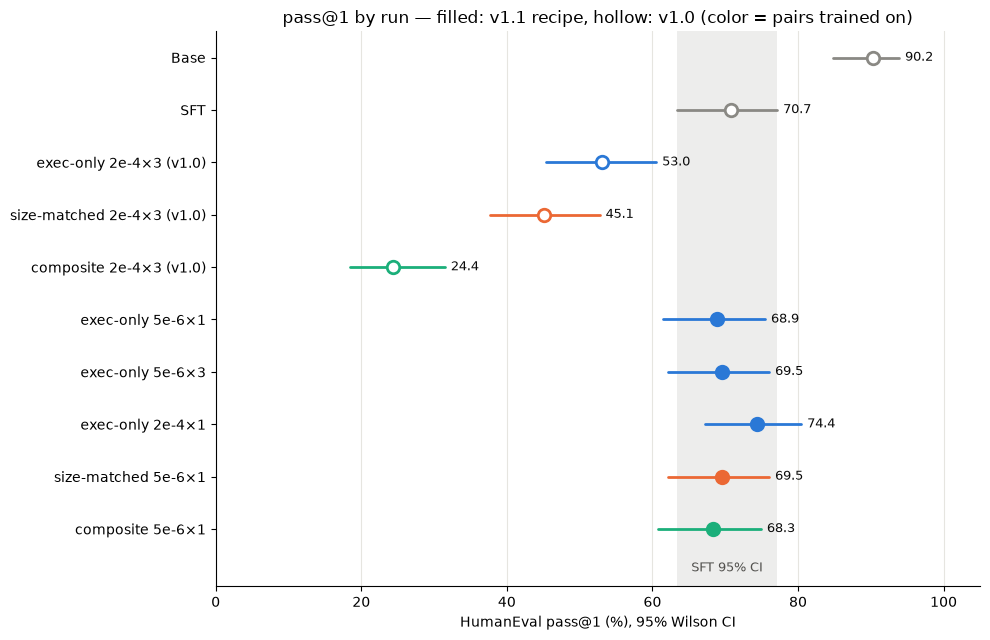

In [6]:
done = results.dropna(subset=["pass@1 (%)"])
if len(done) >= 2:
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(done) + 1.5))
    y = np.arange(len(done))[::-1]
    sft = results.loc["SFT"]
    if not np.isnan(sft["pass@1 (%)"]):
        ax.axvspan(sft["CI low"], sft["CI high"], color="#8a8984", alpha=0.15, lw=0)
        ax.text((sft["CI low"] + sft["CI high"]) / 2, -0.75, "SFT 95% CI", color="#52514e", fontsize=9,
                ha="center", va="center")
    for yi, (label, r) in zip(y, done.iterrows(), strict=True):
        color = ARM_COLORS[RUNS.loc[label, "pairs"]]
        filled = RUNS.loc[label, "version"] == "v1.1"
        ax.plot([r["CI low"], r["CI high"]], [yi, yi], color=color, lw=2, solid_capstyle="round")
        ax.plot(r["pass@1 (%)"], yi, "o", ms=9, color=color, mfc=color if filled else "white", mew=2)
        ax.text(r["CI high"] + 0.8, yi, f"{r['pass@1 (%)']:.1f}", va="center", fontsize=9, color="#0b0b0b")
    ax.set_yticks(y, done.index)
    ax.set_ylim(-1.1, len(done) - 0.5)
    ax.set_xlim(0, 105)
    ax.set_xlabel("HumanEval pass@1 (%), 95% Wilson CI")
    ax.set_title("pass@1 by run — filled: v1.1 recipe, hollow: v1.0 (color = pairs trained on)")
    ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

## 3. H1 — Learning rate × epochs on the execution-only pairs

The four execution-only runs form a 2×2: v1.0's run is the `2e-4 × 3` cell. Holding one factor fixed, each row and column difference isolates the other.

In [7]:
GRID = {("5e-6", 1): "exec-only 5e-6×1", ("5e-6", 3): "exec-only 5e-6×3",
        ("2e-4", 1): "exec-only 2e-4×1", ("2e-4", 3): "exec-only 2e-4×3 (v1.0)"}

def cell(label):
    r = results.loc[label]
    return "pending" if np.isnan(r["pass@1 (%)"]) else f"{r['pass@1 (%)']:.1f} [{r['CI low']:.1f}, {r['CI high']:.1f}]"

grid = pd.DataFrame({f"lr = {lr}": {f"{ep} epoch{'s' if ep > 1 else ''}": cell(GRID[(lr, ep)]) for ep in (1, 3)}
                     for lr in ("5e-6", "2e-4")})
print("pass@1 (%) [95% CI], execution-only pairs:")
display(grid)

def paired(a, b):
    if a not in passes or b not in passes:
        return None
    pa, pb = passes[a], passes[b]
    only_a = sum(x and not y for x, y in zip(pa, pb, strict=True))
    only_b = sum(y and not x for x, y in zip(pa, pb, strict=True))
    return {"Δ (pts)": 100 * (sum(pa) - sum(pb)) / N_PROBLEMS, "only A": only_a, "only B": only_b,
            "McNemar p": mcnemar_exact(pa, pb)}

effects = [("lr 5e-6 vs 2e-4, 1 epoch", GRID[("5e-6", 1)], GRID[("2e-4", 1)]),
           ("lr 5e-6 vs 2e-4, 3 epochs", GRID[("5e-6", 3)], GRID[("2e-4", 3)]),
           ("1 vs 3 epochs, lr 5e-6", GRID[("5e-6", 1)], GRID[("5e-6", 3)]),
           ("1 vs 3 epochs, lr 2e-4", GRID[("2e-4", 1)], GRID[("2e-4", 3)])]
effect_rows = [{"effect": name, "A": a, "B": b, **(paired(a, b) or {"Δ (pts)": "pending"})} for name, a, b in effects]
display(pd.DataFrame(effect_rows).set_index("effect").round(4))

pass@1 (%) [95% CI], execution-only pairs:


,lr = 5e-6,lr = 2e-4
1 epoch,"68.9 [61.5, 75.5]","74.4 [67.2, 80.5]"
3 epochs,"69.5 [62.1, 76.0]","53.0 [45.4, 60.5]"


,A,B,Δ (pts),only A,only B,McNemar p
effect,,,,,,
"lr 5e-6 vs 2e-4, 1 epoch",exec-only 5e-6×1,exec-only 2e-4×1,-5.4878,18,27,0.2327
"lr 5e-6 vs 2e-4, 3 epochs",exec-only 5e-6×3,exec-only 2e-4×3 (v1.0),16.4634,42,15,0.0005
"1 vs 3 epochs, lr 5e-6",exec-only 5e-6×1,exec-only 5e-6×3,-0.6098,1,2,1.0000
"1 vs 3 epochs, lr 2e-4",exec-only 2e-4×1,exec-only 2e-4×3 (v1.0),21.3415,48,13,0.0000


## 4. Paired tests (exact McNemar)

Both models answer the same 164 problems, so the comparison is paired: only the problems one model solves and the other does not carry information. The table lists the comparisons the hypotheses need; the matrix below has every pair of evaluated runs (two-sided exact p; with this many comparisons, treat p values near 0.05 as suggestive).

In [8]:
key = [("exec-only 5e-6×1", "SFT"), ("exec-only 5e-6×1", "exec-only 2e-4×3 (v1.0)"),
       ("size-matched 5e-6×1", "SFT"), ("size-matched 5e-6×1", "size-matched 2e-4×3 (v1.0)"),
       ("composite 5e-6×1", "SFT"), ("composite 5e-6×1", "composite 2e-4×3 (v1.0)"),
       ("size-matched 5e-6×1", "exec-only 5e-6×1"), ("composite 5e-6×1", "size-matched 5e-6×1")]
key += [(label, V10_COUNTERPART[RUNS.loc[label, "pairs"]].replace("2e-4×3 (v1.0)", "5e-6×1"))
        for label in RUNS.index[RUNS["optional"]]]
key_rows = [{"A": a, "B": b, **(paired(a, b) or {"Δ (pts)": "pending"})} for a, b in key if a in RUNS.index]
display(pd.DataFrame(key_rows).set_index(["A", "B"]).round(4))

tested = [label for label in RUNS.index if label in passes]
if len(tested) >= 2:
    matrix = pd.DataFrame("", index=tested, columns=tested)
    for a, b in combinations(tested, 2):
        p = mcnemar_exact(passes[a], passes[b])
        matrix.loc[a, b] = matrix.loc[b, a] = f"{p:.3f}" if p >= 0.001 else "<0.001"
    print("Exact McNemar p, all pairs:")
    display(matrix)

Δ (pts)  only A  only B  \
A                   B                                                     
exec-only 5e-6×1    SFT                         -1.8293      11      14   
                    exec-only 2e-4×3 (v1.0)     15.8537      41      15   
size-matched 5e-6×1 SFT                         -1.2195      11      13   
                    size-matched 2e-4×3 (v1.0)  24.3902      48       8   
composite 5e-6×1    SFT                         -2.4390      14      18   
                    composite 2e-4×3 (v1.0)     43.9024      78       6   
size-matched 5e-6×1 exec-only 5e-6×1             0.6098       3       2   
composite 5e-6×1    size-matched 5e-6×1         -1.2195       6       8   

                                                McNemar p  
A                   B                                      
exec-only 5e-6×1    SFT                            0.6900  
                    exec-only 2e-4×3 (v1.0)        0.0007  
size-matched 5e-6×1 SFT                            0.8388  
                    size-matched 2e-4×3 (v1.0)     0.0000  
composite 5e-6×1    SFT                            0.5966  
                    composite 2e-4×3 (v1.0)        0.0000  
size-matched 5e-6×1 exec-only 5e-6×1               1.0000  
composite 5e-6×1    size-matched 5e-6×1            0.7905

Exact McNemar p, all pairs:


,Base,SFT,exec-only 2e-4×3 (v1.0),size-matched 2e-4×3 (v1.0),composite 2e-4×3 (v1.0),exec-only 5e-6×1,exec-only 5e-6×3,exec-only 2e-4×1,size-matched 5e-6×1,composite 5e-6×1
Base,,<0.001,<0.001,<0.001,<0.001,<0.001,<0.001,<0.001,<0.001,<0.001
SFT,<0.001,,<0.001,<0.001,<0.001,0.690,0.845,0.441,0.839,0.597
exec-only 2e-4×3 (v1.0),<0.001,<0.001,,0.117,<0.001,<0.001,<0.001,<0.001,<0.001,0.002
size-matched 2e-4×3 (v1.0),<0.001,<0.001,0.117,,<0.001,<0.001,<0.001,<0.001,<0.001,<0.001
composite 2e-4×3 (v1.0),<0.001,<0.001,<0.001,<0.001,,<0.001,<0.001,<0.001,<0.001,<0.001
exec-only 5e-6×1,<0.001,0.690,<0.001,<0.001,<0.001,,1.000,0.233,1.000,1.000
exec-only 5e-6×3,<0.001,0.845,<0.001,<0.001,<0.001,1.000,,0.302,1.000,0.754
exec-only 2e-4×1,<0.001,0.441,<0.001,<0.001,<0.001,0.233,0.302,,0.280,0.184
size-matched 5e-6×1,<0.001,0.839,<0.001,<0.001,<0.001,1.000,1.000,0.280,,0.791
composite 5e-6×1,<0.001,0.597,0.002,<0.001,<0.001,1.000,0.754,0.184,0.791,


## 5. Training curves

Reward accuracy and reward margin (chosen − rejected implicit reward) from each run's `trainer_state.json`, against epochs so that runs with different pair counts align. v1.0's runs reached reward accuracy 1.00; under H1 the 5e-6 runs should stay well below that and keep small margins. Rolling mean over 10 logs.

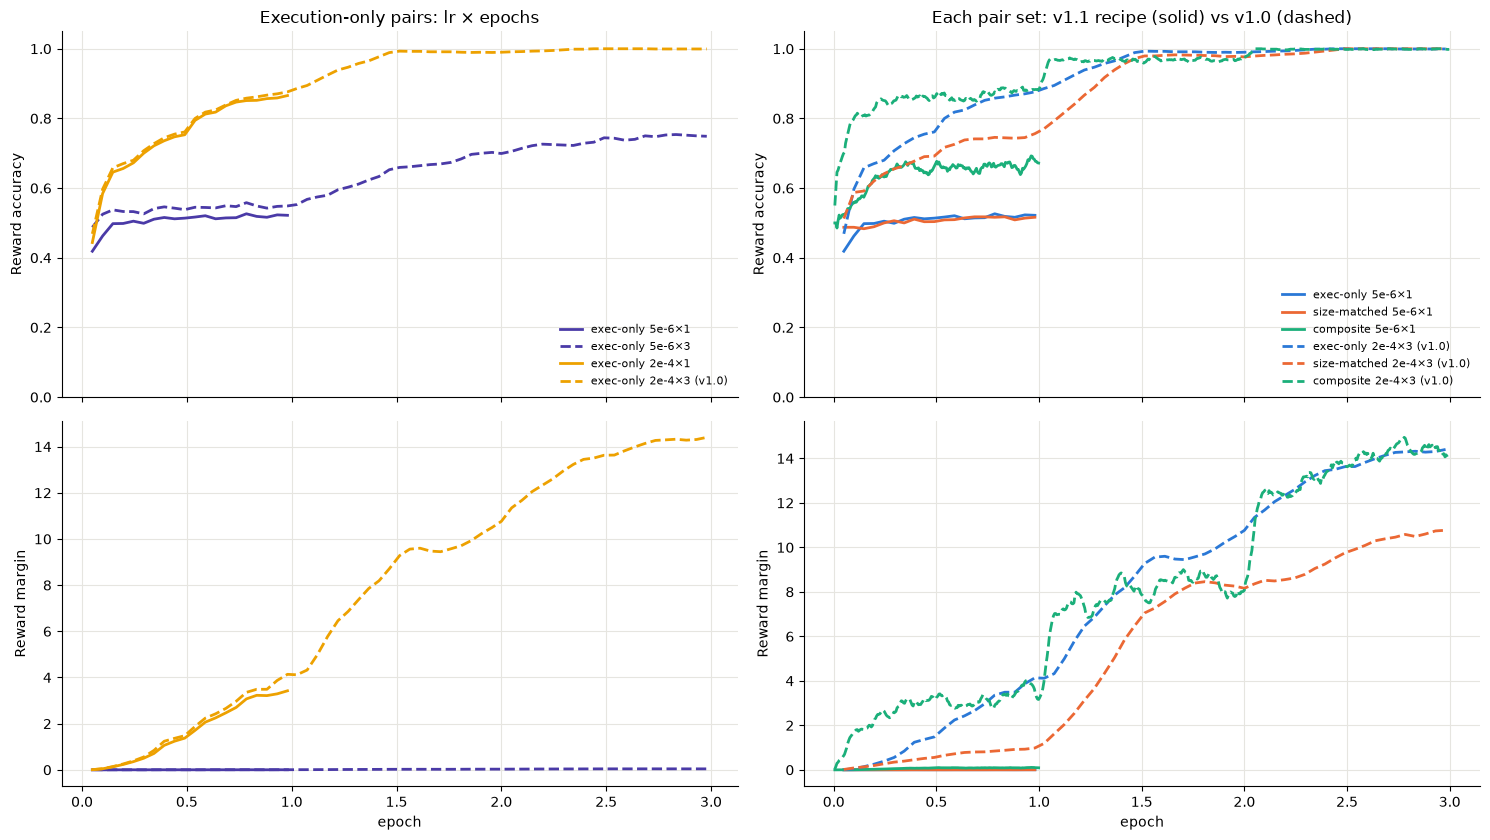

,log entries,Reward accuracy (last 10% of logs),Reward margin (last 10% of logs)
run,,,
exec-only 2e-4×3 (v1.0),61,0.999,14.217
size-matched 2e-4×3 (v1.0),61,1.000,10.679
composite 2e-4×3 (v1.0),574,0.999,14.398
exec-only 5e-6×1,20,0.534,0.006
exec-only 5e-6×3,61,0.741,0.042
exec-only 2e-4×1,20,0.866,3.665
size-matched 5e-6×1,20,0.512,0.002
composite 5e-6×1,191,0.676,0.096


In [9]:
histories = {}
for label, row in RUNS[RUNS["ckpt"].notna()].iterrows():
    path = find_trainer_state(row.ckpt)
    if path is not None:
        histories[label] = load_log_history(path)[0]
missing_curves = [label for label in RUNS.index[RUNS["ckpt"].notna()] if label not in histories]
if missing_curves:
    print("No trainer_state.json for:", missing_curves)

LR_COLORS = {5e-6: "#4a3aa7", 2e-4: "#eda100"}  # validated pair
EPOCH_STYLE = {1: "-", 3: "--"}
panels = {
    "Execution-only pairs: lr × epochs": {label: (LR_COLORS[RUNS.loc[label, "lr"]], EPOCH_STYLE[RUNS.loc[label, "epochs"]])
                                          for label in GRID.values()},
    "Each pair set: v1.1 recipe (solid) vs v1.0 (dashed)": {
        label: (ARM_COLORS[RUNS.loc[label, "pairs"]], "-" if RUNS.loc[label, "version"] == "v1.1" else "--")
        for label in ["exec-only 5e-6×1", "size-matched 5e-6×1", "composite 5e-6×1", *V10_COUNTERPART.values()]},
}
METRICS = [("rewards/accuracies", "Reward accuracy"), ("rewards/margins", "Reward margin")]

if histories:
    fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), sharex="col")
    for col, (title, styles) in enumerate(panels.items()):
        for r, (key, ylabel) in enumerate(METRICS):
            ax = axes[r, col]
            for label, (color, style) in styles.items():
                h = histories.get(label)
                if h is None or key not in h or "epoch" not in h:
                    continue
                s = h.dropna(subset=[key])
                ax.plot(s["epoch"], smooth(s[key]), style, color=color, lw=2, label=label)
            ax.set_ylabel(ylabel)
            ax.grid(color="#e6e5e0", lw=0.8)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            if r == 0:
                ax.set_title(title)
                ax.set_ylim(0, 1.05)
                if ax.get_legend_handles_labels()[0]:
                    ax.legend(fontsize=8, loc="lower right", frameon=False)
            else:
                ax.set_xlabel("epoch")
    plt.tight_layout()
    plt.show()

    curve_rows = []
    for label, h in histories.items():
        row = {"run": label, "log entries": len(h)}
        for key, name in METRICS:
            if key in h and h[key].notna().sum():
                values = h[key].dropna()
                k = max(1, len(values) // 10)
                row[f"{name} (last 10% of logs)"] = values.tail(k).mean()
        curve_rows.append(row)
    display(pd.DataFrame(curve_rows).set_index("run").round(3))

## 6. Verdicts

Generated from the numbers above with the decision rules stated at the top. The README's v1.1 results use exactly this strength.

In [10]:
def ok(label):
    return label in passes and not np.isnan(results.loc[label, "pass@1 (%)"])

print("H1 — over-optimization")
x, x10, sft = "exec-only 5e-6×1", "exec-only 2e-4×3 (v1.0)", results.loc["SFT"]
if ok(x) and ok("SFT") and ok(x10):
    r = results.loc[x]
    inside = sft["CI low"] <= r["pass@1 (%)"] <= sft["CI high"]
    gap = sft["pass@1 (%)"] - results.loc[x10, "pass@1 (%)"]
    recovered = (r["pass@1 (%)"] - results.loc[x10, "pass@1 (%)"]) / gap if gap else np.nan
    vs_sft, vs_v10 = paired(x, "SFT"), paired(x, x10)
    print(f"- {x}: {r['pass@1 (%)']:.1f}% vs SFT {sft['pass@1 (%)']:.1f}% [{sft['CI low']:.1f}, {sft['CI high']:.1f}] → "
          f"{'inside' if inside else 'outside'} SFT's CI; recovers {100 * recovered:.0f}% of v1.0's gap to SFT")
    print(f"- vs SFT: Δ {vs_sft['Δ (pts)']:+.1f} pts, McNemar p = {vs_sft['McNemar p']:.3g}; "
          f"vs v1.0 exec-only: Δ {vs_v10['Δ (pts)']:+.1f} pts, p = {vs_v10['McNemar p']:.3g}")
    better = vs_v10["Δ (pts)"] > 0 and vs_v10["McNemar p"] < ALPHA
    if inside and better:
        print("→ H1 supported: the v1.0 recipe, not the pairs, explains the execution-only arm's drop.")
    elif better:
        print("→ H1 partly supported: the gentler recipe recovers part of the drop; the rest points at the pairs (H2).")
    else:
        print("→ H1 not supported: the gentler recipe does not recover pass@1, so the pairs themselves are harmful (H2, v2.2).")
    for name, a, b in effects:
        e = paired(a, b)
        if e:
            print(f"  · {name}: Δ {e['Δ (pts)']:+.1f} pts (p = {e['McNemar p']:.3g})")
else:
    print("- pending: needs SFT, v1.0 exec-only and exec-only 5e-6×1 (metrics + per-problem results)")

print("\nH2 — no-op chosen candidates (Case A, any flag)")
if h2_rows:
    for r in h2_rows:
        supported = r["ratio"] >= H2_MIN_RATIO and r["McNemar p"] < ALPHA
        print(f"- {r['file']}: chosen {r['chosen flagged (%)']:.1f}% vs rejected {r['rejected flagged (%)']:.1f}% "
              f"(×{r['ratio']:.1f}, p = {r['McNemar p']:.3g}) → {'supported' if supported else 'not supported'}")
else:
    print("- pending: run scripts/audit_preference_pairs.py")
for label in RUNS.index[RUNS["optional"]]:
    base = V10_COUNTERPART[RUNS.loc[label, "pairs"]].replace("2e-4×3 (v1.0)", "5e-6×1")
    e = paired(label, base)
    if e:
        print(f"- causal check, {label} vs {base}: Δ {e['Δ (pts)']:+.1f} pts (p = {e['McNemar p']:.3g})")

print("\nNo-op rate of the evaluated solutions (all comments, or entry point never defined)")
for label in RUNS.index:
    if label in noop_counts:
        print(f"- {label}: {noop_counts[label]}/{N_PROBLEMS} ({100 * noop_counts[label] / N_PROBLEMS:.1f}%)")

if eval_warnings or train_warnings:
    print(f"\n⚠ {len(eval_warnings) + len(train_warnings)} provenance warning(s) in §0 — resolve before quoting any number")

H1 — over-optimization
- exec-only 5e-6×1: 68.9% vs SFT 70.7% [63.4, 77.2] → inside SFT's CI; recovers 90% of v1.0's gap to SFT
- vs SFT: Δ -1.8 pts, McNemar p = 0.69; vs v1.0 exec-only: Δ +15.9 pts, p = 0.000686
→ H1 supported: the v1.0 recipe, not the pairs, explains the execution-only arm's drop.
  · lr 5e-6 vs 2e-4, 1 epoch: Δ -5.5 pts (p = 0.233)
  · lr 5e-6 vs 2e-4, 3 epochs: Δ +16.5 pts (p = 0.00046)
  · 1 vs 3 epochs, lr 5e-6: Δ -0.6 pts (p = 1)
  · 1 vs 3 epochs, lr 2e-4: Δ +21.3 pts (p = 7.67e-06)

H2 — no-op chosen candidates (Case A, any flag)
- dpo_report.jsonl: chosen 3.6% vs rejected 1.7% (×2.1, p = 3.81e-08) → supported
- dpo_report_exec_only.jsonl: chosen 3.0% vs rejected 1.3% (×2.4, p = 7.34e-08) → supported

No-op rate of the evaluated solutions (all comments, or entry point never defined)
- Base: 2/164 (1.2%)
- SFT: 0/164 (0.0%)
- exec-only 2e-4×3 (v1.0): 34/164 (20.7%)
- size-matched 2e-4×3 (v1.0): 9/164 (5.5%)
- composite 2e-4×3 (v1.0): 32/164 (19.5%)
- exec-only 